# Grupo 19 — Árbol de decisión corregido (Entrega 3)


In [1]:
from pathlib import Path
from hashlib import sha256
import os
import json
import warnings
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, RandomizedSearchCV
from sklearn.metrics import (
    average_precision_score, roc_auc_score, precision_score, recall_score,
    f1_score, confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve
)

try:
    import mlflow
    MLFLOW_DISPONIBLE = True
except ImportError:
    mlflow = None
    MLFLOW_DISPONIBLE = False
    print('AVISO: falta mlflow. Instala con %pip install mlflow y reinicia el kernel.')

SEED = 42
N_ITER_BUSQUEDA = 32  # aumentar a 60 si hay tiempo/recursos
N_FOLDS = 4
RUTA_CSV = str(Path.home() / "Downloads" / "ELCO_2022_creditos_ahorro_laboral_consolidado.csv")
NOMBRE_CSV = 'ELCO_2022_creditos_ahorro_laboral_consolidado.csv'
# Para EC2: export MLFLOW_TRACKING_URI=http://IP_O_DNS_EC2:8050
MLFLOW_TRACKING_URI = "http://127.0.0.1:5000"


ROOT = Path.cwd()
CANDIDATOS = [
    Path(RUTA_CSV).expanduser() if RUTA_CSV.strip() else None,
    Path(os.environ['ELCO_CSV']).expanduser() if os.environ.get('ELCO_CSV') else None,
    ROOT / NOMBRE_CSV,
    ROOT / 'data' / NOMBRE_CSV,
    ROOT.parent / 'data' / NOMBRE_CSV,
    Path('/dbfs/FileStore') / NOMBRE_CSV,
]
RUTA = next((p for p in CANDIDATOS if p is not None and p.is_file()), None)
if RUTA is None:
    raise FileNotFoundError(
        'No encuentro el CSV. Modifica RUTA_CSV con la ruta de Databricks o '
        'pon el archivo en la carpeta data/ del repositorio.'
    )
OUT = (Path('/tmp/resultados_arbol_Nicole_E3')
       if os.environ.get('DATABRICKS_RUNTIME_VERSION')
       else ROOT / 'resultados_arbol_Nicole_E3')
OUT.mkdir(parents=True, exist_ok=True)

with open(RUTA, 'rb') as f:
    HASH_DATOS = sha256(f.read()).hexdigest()
df = pd.read_csv(RUTA, low_memory=False)
print('Datos:', RUTA, '| registros:', len(df), '| hogares:', df.DIRECTORIO.nunique())
print('Carpeta de salida:', OUT)

Datos: C:\Users\nicol\Downloads\ELCO_2022_creditos_ahorro_laboral_consolidado.csv | registros: 4013 | hogares: 3020
Carpeta de salida: c:\Users\nicol\Downloads\resultados_arbol_Nicole_E3


## 1. Variables, limpieza y controles contra fuga de información


In [2]:
OBJETIVO = 'objetivo_atraso'
GRUPO = 'DIRECTORIO'
CATEGORICAS = ['P2097', 'P2098', 'P2106']
NUMERICAS_A = ['P2099S2', 'P2104', 'P2105S1', 'P2107S1']
HOGAR = [
    'n_personas_ahorro', 'n_personas_con_ingresos',
    'n_personas_que_ahorran', 'prop_que_ahorran_sobre_con_ingresos',
    'n_personas_con_cuenta', 'n_personas_laboral',
    'n_personas_trabajo_semana'
]
VARIABLES = {'A': CATEGORICAS + NUMERICAS_A,
             'B': CATEGORICAS + NUMERICAS_A + HOGAR}
NECESARIAS = set(VARIABLES['B'] + [OBJETIVO, GRUPO, 'P2110'])
faltantes = NECESARIAS - set(df.columns)
if faltantes:
    raise ValueError(f'Columnas ausentes en CSV: {sorted(faltantes)}')

base = df.copy()
base['P2107S1'] = pd.to_numeric(base['P2107S1'], errors='coerce').replace(9999, np.nan)
for c in VARIABLES['B']:
    if c not in CATEGORICAS:
        base[c] = pd.to_numeric(base[c], errors='coerce')
    else:
        base[c] = base[c].astype('string').replace({'<NA>': pd.NA}).astype(object)
        base[c] = base[c].where(pd.notna(base[c]), np.nan)
base[OBJETIVO] = pd.to_numeric(base[OBJETIVO], errors='raise').astype(int)
if not base[OBJETIVO].isin([0, 1]).all():
    raise ValueError('La etiqueta debe ser binaria 0/1')
if not (base[OBJETIVO] == (base['P2110'] == 2).astype(int)).all():
    raise ValueError('La etiqueta no coincide con P2110==2; revisar datos.')
if base[GRUPO].isna().any():
    raise ValueError('DIRECTORIO tiene valores nulos.')
assert not {'P2110', 'P2108', GRUPO, OBJETIVO}.intersection(VARIABLES['B'])
print('Tasa base de retraso:', round(base[OBJETIVO].mean(), 4))
print('Variables A:', VARIABLES['A'])
print('Variables B adicionales:', HOGAR)

Tasa base de retraso: 0.1682
Variables A: ['P2097', 'P2098', 'P2106', 'P2099S2', 'P2104', 'P2105S1', 'P2107S1']
Variables B adicionales: ['n_personas_ahorro', 'n_personas_con_ingresos', 'n_personas_que_ahorran', 'prop_que_ahorran_sobre_con_ingresos', 'n_personas_con_cuenta', 'n_personas_laboral', 'n_personas_trabajo_semana']


## 2. Partición por hogar 70/15/15

In [3]:
gss = GroupShuffleSplit(n_splits=1, test_size=.30, random_state=SEED)
i_train, i_temp = next(gss.split(base, base[OBJETIVO], groups=base[GRUPO]))
train = base.iloc[i_train].copy()
temporal = base.iloc[i_temp].copy()
gss2 = GroupShuffleSplit(n_splits=1, test_size=.50, random_state=SEED + 1)
i_val, i_test = next(gss2.split(temporal, temporal[OBJETIVO], groups=temporal[GRUPO]))
val = temporal.iloc[i_val].copy()
test = temporal.iloc[i_test].copy()
for p1, p2 in [(train, val), (train, test), (val, test)]:
    assert set(p1[GRUPO]).isdisjoint(set(p2[GRUPO]))
for nombre, parte in [('Entrenamiento', train), ('Validación', val), ('Prueba', test)]:
    assert parte[OBJETIVO].nunique() == 2, f'Falta una clase en {nombre}'
    print(f'{nombre}: {len(parte)} créditos, {parte[GRUPO].nunique()} hogares, '
          f'retrasos={parte[OBJETIVO].mean():.3%}')

particiones = pd.concat([
    pd.DataFrame({'indice_fila': p.index, 'DIRECTORIO': p[GRUPO].to_numpy(),
                  'particion': nombre, 'objetivo_atraso': p[OBJETIVO].to_numpy()})
    for nombre, p in [('train', train), ('val', val), ('test', test)]
]).sort_values('indice_fila')
particiones.to_csv(OUT / 'particiones_comunes_grupo19.csv', index=False)
y_train, y_val, y_test = (p[OBJETIVO].astype(int) for p in (train, val, test))

Entrenamiento: 2808 créditos, 2114 hogares, retrasos=17.308%
Validación: 613 créditos, 453 hogares, retrasos=15.334%
Prueba: 592 créditos, 453 hogares, retrasos=16.047%


## 3. Pipeline y métricas

In [4]:
def crear_pipeline(variables, **parametros_arbol):
    cats = [c for c in CATEGORICAS if c in variables]
    nums = [c for c in variables if c not in cats]
    prep = ColumnTransformer([
        ('num', Pipeline([('imputar', SimpleImputer(strategy='median', add_indicator=True))]), nums),
        ('cat', Pipeline([('imputar', SimpleImputer(strategy='most_frequent')),
                          ('ohe', OneHotEncoder(handle_unknown='ignore'))]), cats)
    ])
    modelo = DecisionTreeClassifier(random_state=SEED, **parametros_arbol)
    return Pipeline([('preparacion', prep), ('modelo', modelo)])

UMBRALES = np.round(np.arange(0.10, 0.901, 0.025), 3)

def seleccionar_umbral(y_real, prob):
    scores = np.array([f1_score(y_real, prob >= u, zero_division=0) for u in UMBRALES])
    return float(UMBRALES[int(np.argmax(scores))])

def calcular_metricas(y_real, prob, umbral):
    pred = (prob >= umbral).astype(int)
    return {
        'pr_auc': float(average_precision_score(y_real, prob)),
        'roc_auc': float(roc_auc_score(y_real, prob)),
        'precision': float(precision_score(y_real, pred, zero_division=0)),
        'recall': float(recall_score(y_real, pred, zero_division=0)),
        'f1': float(f1_score(y_real, pred, zero_division=0)),
        'umbral': float(umbral),
    }

if MLFLOW_DISPONIBLE:
    if MLFLOW_TRACKING_URI:
        mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
    else:
        mlflow.set_tracking_uri((OUT / 'mlruns').resolve().as_uri())
        print('AVISO: MLflow local. Para evidencias de EC2 configura MLFLOW_TRACKING_URI.')
    mlflow.set_experiment('Grupo19_ArbolDecision_Nicole_Entrega3')


def registrar_run(nombre, params, metrics, etapa):
    if not MLFLOW_DISPONIBLE:
        return
    with mlflow.start_run(run_name=nombre):
        mlflow.set_tags({'integrante': 'Nicole', 'modelo': 'DecisionTreeClassifier',
                         'etapa': etapa, 'hash_datos': HASH_DATOS[:16],
                         'split_seed': str(SEED)})
        mlflow.log_params({k: str(v) for k, v in params.items()})
        mlflow.log_metrics({k: float(v) for k, v in metrics.items()
                            if isinstance(v, (int, float, np.integer, np.floating))})

2026/11/23 23:20:57 INFO mlflow.tracking.fluent: Experiment with name 'Grupo19_ArbolDecision_Nicole_Entrega3' does not exist. Creating a new experiment.


## 4. Reproducir los 6 experimentos originales (línea base)

In [5]:
registros = []
modelos = {}
for grupo, variables in VARIABLES.items():
    for profundidad in [3, 5, 10]:
        nombre = f'BASE_{grupo}_prof_{profundidad}'
        params = {'max_depth': profundidad, 'min_samples_leaf': 5,
                  'class_weight': 'balanced'}
        pipe = crear_pipeline(variables, **params)
        pipe.fit(train[variables], y_train)
        proba = pipe.predict_proba(val[variables])[:, 1]
        umbral = seleccionar_umbral(y_val, proba)
        met = calcular_metricas(y_val, proba, umbral)
        registros.append({'nombre': nombre, 'tipo': 'Original', 'grupo': grupo,
                          **met, **params})
        modelos[nombre] = pipe
        registrar_run(nombre, {'grupo': grupo, **params},
                      {f'val_{k}': v for k, v in met.items()}, 'baseline')
resultados_base = pd.DataFrame(registros)
print('\nRESULTADOS ORIGINALES REPRODUCIDOS EN VALIDACIÓN:')
print(resultados_base.sort_values('pr_auc', ascending=False).round(4).to_string(index=False))

🏃 View run BASE_A_prof_3 at: http://127.0.0.1:5000/#/experiments/2/runs/37b102509ec042f5b00214489247f516
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
🏃 View run BASE_A_prof_5 at: http://127.0.0.1:5000/#/experiments/2/runs/c8c42e532d7c469d93bc84f7aca5a455
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
🏃 View run BASE_A_prof_10 at: http://127.0.0.1:5000/#/experiments/2/runs/b9062898d1f3427b8f4ce2a5327aec2d
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
🏃 View run BASE_B_prof_3 at: http://127.0.0.1:5000/#/experiments/2/runs/91b37b7c11bc44169ac316d495e89b4b
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
🏃 View run BASE_B_prof_5 at: http://127.0.0.1:5000/#/experiments/2/runs/2c3982d8c8354ab9a7380868ba36ba92
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
🏃 View run BASE_B_prof_10 at: http://127.0.0.1:5000/#/experiments/2/runs/84a3a02644af46208f59713076098098
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2

RESULTA

## 5. Búsqueda ampliada con validación cruzada agrupada por hogar

In [6]:
ESPACIO = {
    'modelo__max_depth': [3, 5, 7, 10, 15, None],
    'modelo__min_samples_leaf': [2, 5, 10, 20, 40],
    'modelo__min_samples_split': [2, 10, 20, 40],
    'modelo__criterion': ['gini', 'entropy'],
    'modelo__class_weight': [None, 'balanced'],
    'modelo__ccp_alpha': [0.0, 0.0005, 0.002],
}
cv = GroupKFold(n_splits=N_FOLDS)
resultados_busqueda = []
registros_opt = []
for grupo, variables in VARIABLES.items():
    print(f'\nBuscando hiperparámetros para modelo {grupo}...')
    pipe = crear_pipeline(variables)
    search = RandomizedSearchCV(
        estimator=pipe, param_distributions=ESPACIO,
        n_iter=N_ITER_BUSQUEDA, scoring='average_precision',
        cv=cv, refit=True, random_state=SEED,
        n_jobs=-1, verbose=0, error_score='raise', return_train_score=False
    )
    search.fit(train[variables], y_train, groups=train[GRUPO])
    cv_tabla = pd.DataFrame(search.cv_results_)
    for i, r in cv_tabla.iterrows():
        params = dict(r['params'])
        registro = {'grupo': grupo, 'iteracion': int(i+1),
                    'pr_auc_cv': float(r['mean_test_score']),
                    'std_pr_auc_cv': float(r['std_test_score']),
                    **params}
        resultados_busqueda.append(registro)
        registrar_run(f'OPT_{grupo}_cv_{i+1:02d}',
                      {'grupo': grupo, **params},
                      {'cv_pr_auc': r['mean_test_score'],
                       'cv_std_pr_auc': r['std_test_score']}, 'busqueda_cv')
    nombre = f'OPT_{grupo}'
    mejor = search.best_estimator_
    proba = mejor.predict_proba(val[variables])[:, 1]
    umbral = seleccionar_umbral(y_val, proba)
    met = calcular_metricas(y_val, proba, umbral)
    registros_opt.append({'nombre': nombre, 'tipo': 'Optimizado', 'grupo': grupo,
                          **met, 'pr_auc_cv': float(search.best_score_),
                          **{k.replace('modelo__', ''): v for k, v in search.best_params_.items()}})
    modelos[nombre] = mejor
    registrar_run(nombre, {'grupo': grupo, **search.best_params_},
                  {**{f'val_{k}': v for k, v in met.items()},
                   'cv_pr_auc': search.best_score_}, 'mejor_optimizado')
    print(f'{grupo}: CV PR-AUC={search.best_score_:.4f}, '
          f'validación PR-AUC={met["pr_auc"]:.4f}, umbral={umbral:.3f}')

pd.DataFrame(resultados_busqueda).to_csv(OUT / 'busqueda_hiperparametros_cv.csv', index=False)
resultados_opt = pd.DataFrame(registros_opt)
resultados = pd.concat([resultados_base, resultados_opt], ignore_index=True)
resultados.to_csv(OUT / 'comparacion_validacion_todos.csv', index=False)


Buscando hiperparámetros para modelo A...
🏃 View run OPT_A_cv_01 at: http://127.0.0.1:5000/#/experiments/2/runs/71ced8ce295f44288c8dcd20921b6569
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
🏃 View run OPT_A_cv_02 at: http://127.0.0.1:5000/#/experiments/2/runs/6689794e119b4cccbc67fa296bd5b986
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
🏃 View run OPT_A_cv_03 at: http://127.0.0.1:5000/#/experiments/2/runs/f616b8bb27934695aff09303a777c298
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
🏃 View run OPT_A_cv_04 at: http://127.0.0.1:5000/#/experiments/2/runs/b20f476a991c4d7bad58b800a20a8a75
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
🏃 View run OPT_A_cv_05 at: http://127.0.0.1:5000/#/experiments/2/runs/a2d5bb4ed7134c0697cbe31fc0c5bb02
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
🏃 View run OPT_A_cv_06 at: http://127.0.0.1:5000/#/experiments/2/runs/6c93812f944a4a549ec5c7b9310a8443
🧪 View experiment at: http://127.0.0.1:

## 6. Mostrar la mejora real: original vs optimizado (MISMA VALIDACIÓN)


COMPARACIÓN DE MEJORA (VALIDACIÓN):
Conjunto Mejor original  PR-AUC original  PR-AUC optimizado  Diferencia ¿Mejoró?
       A  BASE_A_prof_5           0.3685             0.3413     -0.0272       NO
       B  BASE_B_prof_5           0.3627             0.3195     -0.0432       NO


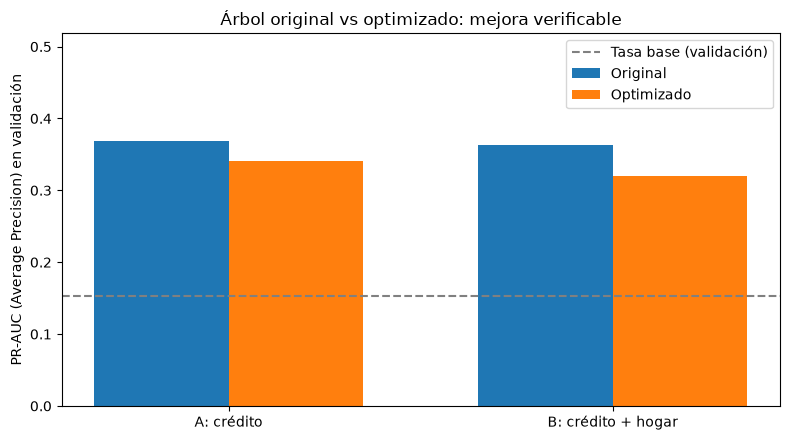

In [7]:
filas = []
for grupo in ['A', 'B']:
    anterior = resultados_base[resultados_base.grupo == grupo].sort_values('pr_auc', ascending=False).iloc[0]
    nuevo = resultados_opt[resultados_opt.grupo == grupo].iloc[0]
    filas.append({'Conjunto': grupo,
                  'Mejor original': anterior['nombre'],
                  'PR-AUC original': float(anterior['pr_auc']),
                  'PR-AUC optimizado': float(nuevo['pr_auc']),
                  'Diferencia': float(nuevo['pr_auc'] - anterior['pr_auc']),
                  '¿Mejoró?': 'SÍ' if nuevo['pr_auc'] > anterior['pr_auc'] else 'NO'})
mejoras = pd.DataFrame(filas)
mejoras.to_csv(OUT / 'mejora_original_vs_optimizado.csv', index=False)
print('\nCOMPARACIÓN DE MEJORA (VALIDACIÓN):')
print(mejoras.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(2)
w = .35
ax.bar(x-w/2, mejoras['PR-AUC original'], w, label='Original')
ax.bar(x+w/2, mejoras['PR-AUC optimizado'], w, label='Optimizado')
ax.axhline(y_val.mean(), ls='--', color='gray', label='Tasa base (validación)')
ax.set_xticks(x, ['A: crédito', 'B: crédito + hogar'])
ax.set_ylabel('PR-AUC (Average Precision) en validación')
ax.set_title('Árbol original vs optimizado: mejora verificable')
ax.legend()
ax.set_ylim(0, min(1, max(mejoras['PR-AUC original'].max(),
                          mejoras['PR-AUC optimizado'].max()) + .15))
plt.tight_layout()
fig.savefig(OUT / '01_comparacion_mejora_validacion.png', dpi=180)
plt.show()

## 7. Elegir un único árbol final y evaluar TEST una sola vez

In [8]:
ordenados = resultados.sort_values(['pr_auc', 'f1'], ascending=[False, False])
ganador = ordenados.iloc[0]
nombre_ganador = str(ganador['nombre'])
grupo_ganador = str(ganador['grupo'])
variables_ganador = VARIABLES[grupo_ganador]
modelo_final = modelos[nombre_ganador]
umbral_final = float(ganador['umbral'])

prob_test = modelo_final.predict_proba(test[variables_ganador])[:, 1]
pred_test = (prob_test >= umbral_final).astype(int)
met_test = calcular_metricas(y_test, prob_test, umbral_final)
print('\nÁRBOL SELECCIONADO (POR VALIDACIÓN):', nombre_ganador)
print('Grupo de variables:', grupo_ganador)
print('Umbral (definido en validación):', umbral_final)
print('MÉTRICAS FINALES EN PRUEBA:')
print(pd.Series(met_test).round(4).to_string())
pd.DataFrame([{'nombre': nombre_ganador, 'grupo': grupo_ganador,
               **met_test}]).to_csv(OUT / 'metricas_finales_prueba.csv', index=False)


ÁRBOL SELECCIONADO (POR VALIDACIÓN): BASE_A_prof_5
Grupo de variables: A
Umbral (definido en validación): 0.6
MÉTRICAS FINALES EN PRUEBA:
pr_auc       0.3420
roc_auc      0.6893
precision    0.2895
recall       0.4632
f1           0.3563
umbral       0.6000


## 8. Interpretación de negocio: priorizar créditos


In [9]:
priorizacion = []
orden = np.argsort(-prob_test, kind='stable')
y_ordenado = y_test.to_numpy()[orden]
for fraccion in [0.10, 0.20, 0.30]:
    n = max(1, int(np.ceil(len(test) * fraccion)))
    encontrados = int(y_ordenado[:n].sum())
    precision_top = encontrados / n
    recall_top = encontrados / int(y_test.sum())
    priorizacion.append({
        'porcentaje_revisado': int(fraccion * 100),
        'creditos_revisados': n,
        'retrasos_encontrados': encontrados,
        'precision_top': precision_top,
        'recall_top': recall_top,
        'creditos_por_retraso': n / encontrados if encontrados else np.nan,
    })
tabla_prioridad = pd.DataFrame(priorizacion)
print('\nPRIORIZACIÓN DE CRÉDITOS (PRUEBA):')
print(tabla_prioridad.round(3).to_string(index=False))
tabla_prioridad.to_csv(OUT / 'priorizacion_creditos_prueba.csv', index=False)


PRIORIZACIÓN DE CRÉDITOS (PRUEBA):
 porcentaje_revisado  creditos_revisados  retrasos_encontrados  precision_top  recall_top  creditos_por_retraso
                  10                  60                    25          0.417       0.263                 2.400
                  20                 119                    42          0.353       0.442                 2.833
                  30                 178                    47          0.264       0.495                 3.787


## 9. Gráficas de evaluación final

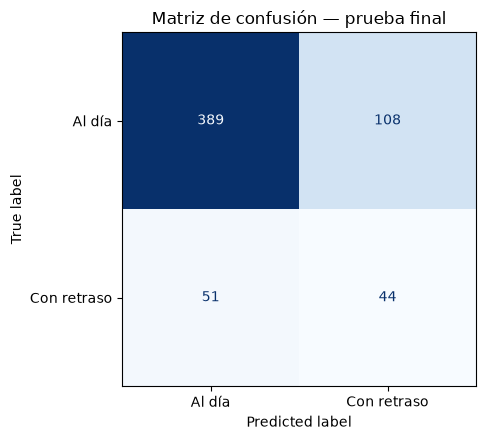

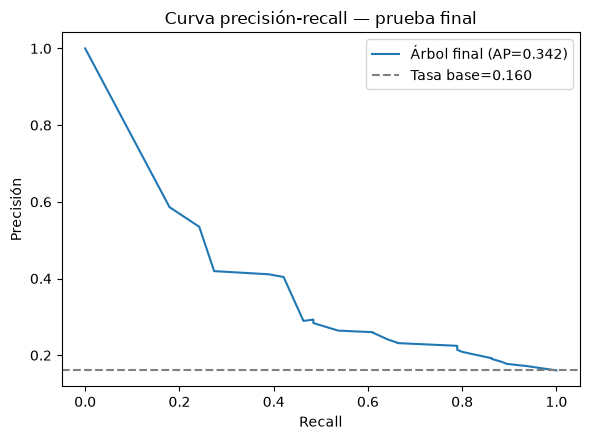

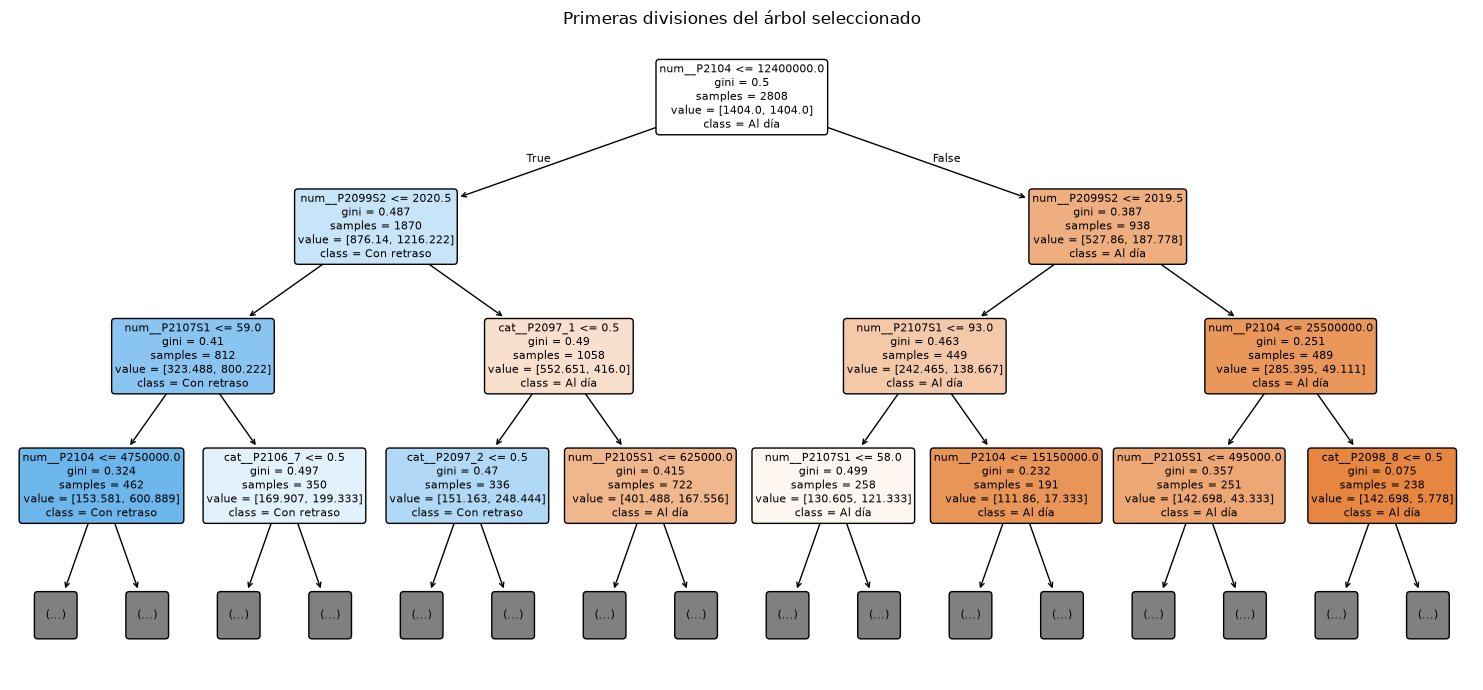

In [10]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_test, labels=[0, 1]),
                       display_labels=['Al día', 'Con retraso']).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Matriz de confusión — prueba final')
plt.tight_layout()
fig.savefig(OUT / '02_matriz_confusion_prueba.png', dpi=180)
plt.show()

p_curve, r_curve, _ = precision_recall_curve(y_test, prob_test)
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(r_curve, p_curve, label=f'Árbol final (AP={met_test["pr_auc"]:.3f})')
ax.axhline(y_test.mean(), ls='--', color='gray', label=f'Tasa base={y_test.mean():.3f}')
ax.set_xlabel('Recall')
ax.set_ylabel('Precisión')
ax.set_title('Curva precisión-recall — prueba final')
ax.legend()
plt.tight_layout()
fig.savefig(OUT / '03_curva_precision_recall_prueba.png', dpi=180)
plt.show()

# Árbol simplificado para interpretación; el pipeline completo se guarda abajo.
fig, ax = plt.subplots(figsize=(15, 7))
try:
    nombres_features = modelo_final.named_steps['preparacion'].get_feature_names_out()
    plot_tree(modelo_final.named_steps['modelo'], max_depth=3,
              feature_names=nombres_features, class_names=['Al día', 'Con retraso'],
              filled=True, rounded=True, fontsize=8, ax=ax)
except Exception as exc:
    print('No se pudo mostrar nombres de variables:', exc)
    plot_tree(modelo_final.named_steps['modelo'], max_depth=3,
              filled=True, rounded=True, fontsize=8, ax=ax)
ax.set_title('Primeras divisiones del árbol seleccionado')
plt.tight_layout()
fig.savefig(OUT / '04_arbol_seleccionado.png', dpi=150)
plt.show()

## 10. Exportar pipeline y metadatos para la API


In [11]:
ruta_modelo = OUT / 'arbol_decision_pipeline_final.joblib'
joblib.dump(modelo_final, ruta_modelo)
metadata = {
    'algoritmo': 'DecisionTreeClassifier',
    'modelo_seleccionado': nombre_ganador,
    'grupo': grupo_ganador,
    'variables': variables_ganador,
    'categoricas': [c for c in CATEGORICAS if c in variables_ganador],
    'umbral': umbral_final,
    'semilla': SEED,
    'sha256_csv': HASH_DATOS,
    'metrica_seleccion': 'pr_auc_validacion',
    'metricas_prueba': met_test,
    'tasa_base_prueba': float(y_test.mean()),
}
with open(OUT / 'metadata_modelo_final.json', 'w', encoding='utf-8') as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False)

if MLFLOW_DISPONIBLE:
    with mlflow.start_run(run_name=f'FINAL_{nombre_ganador}'):
        mlflow.set_tags({'integrante': 'Nicole', 'fase': 'modelo_final',
                         'hash_datos': HASH_DATOS[:16]})
        mlflow.log_params({'nombre': nombre_ganador, 'grupo': grupo_ganador,
                           'umbral': umbral_final, 'seed': SEED})
        mlflow.log_metrics({f'test_{k}': float(v) for k, v in met_test.items()})
        for nombre_archivo in [
            'arbol_decision_pipeline_final.joblib', 'metadata_modelo_final.json',
            'comparacion_validacion_todos.csv', 'mejora_original_vs_optimizado.csv',
            'metricas_finales_prueba.csv', 'priorizacion_creditos_prueba.csv',
            '01_comparacion_mejora_validacion.png', '02_matriz_confusion_prueba.png',
            '03_curva_precision_recall_prueba.png', '04_arbol_seleccionado.png'
        ]:
            mlflow.log_artifact(str(OUT / nombre_archivo))

# Verificación: el artefacto guardado produce las mismas probabilidades.
recargado = joblib.load(ruta_modelo)
assert np.allclose(recargado.predict_proba(test[variables_ganador])[:, 1], prob_test)
print('\nLISTO. Archivos generados en:', OUT)
print('Modelo:', ruta_modelo)
print('Metadata:', OUT / 'metadata_modelo_final.json')
print('Tabla de mejoras:', OUT / 'mejora_original_vs_optimizado.csv')
print('Recuerda: comparar este candidato con regresión logística y Gradient Boosting.')

🏃 View run FINAL_BASE_A_prof_5 at: http://127.0.0.1:5000/#/experiments/2/runs/26bae2a2358a41f48438a361c8a3fe81
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2

LISTO. Archivos generados en: c:\Users\nicol\Downloads\resultados_arbol_Nicole_E3
Modelo: c:\Users\nicol\Downloads\resultados_arbol_Nicole_E3\arbol_decision_pipeline_final.joblib
Metadata: c:\Users\nicol\Downloads\resultados_arbol_Nicole_E3\metadata_modelo_final.json
Tabla de mejoras: c:\Users\nicol\Downloads\resultados_arbol_Nicole_E3\mejora_original_vs_optimizado.csv
Recuerda: comparar este candidato con regresión logística y Gradient Boosting.
